# Fandango Rating Inflation

In October 2015, a journalist named Walt Hickey wrote an article exposing the bias in Fandango's rating system. There was a discrepancy in the number of stars displayed to users and the actual rating in the HTML of the website, with the displayed rating being higher than the actal one. In this notebook, we will try to analyse newer movie rating data to find out if Fandango has made any changes to their rating system after Hickey's publication.

## Data Exploration

In [1]:
# https://www.dataquest.io/projects/guided-project-a-investigative-statistical-analysis-analyzing-accuracy-in-data-presentation/
import pandas as pd

# Source: https://github.com/fivethirtyeight/data/tree/master/fandango
hickey_data = pd.read_csv('datasets/fandango_score_comparison.csv')

# Source: https://github.com/mircealex/Movie_ratings_2016_17
new_data = pd.read_csv('datasets/movie_ratings_16_17.csv')

In [2]:
print(hickey_data.shape, new_data.shape)

(146, 22) (214, 15)


In [3]:
hickey_data.head()

,FILM,RottenTomatoes,RottenTomatoes_User,Metacritic,Metacritic_User,IMDB,Fandango_Stars,Fandango_Ratingvalue,RT_norm,RT_user_norm,...,IMDB_norm,RT_norm_round,RT_user_norm_round,Metacritic_norm_round,Metacritic_user_norm_round,IMDB_norm_round,Metacritic_user_vote_count,IMDB_user_vote_count,Fandango_votes,Fandango_Difference
0,Avengers: Age of Ultron (2015),74,86,66,7.1,7.8,5.0,4.5,3.70,4.3,...,3.90,3.5,4.5,3.5,3.5,4.0,1330,271107,14846,0.5
1,Cinderella (2015),85,80,67,7.5,7.1,5.0,4.5,4.25,4.0,...,3.55,4.5,4.0,3.5,4.0,3.5,249,65709,12640,0.5
2,Ant-Man (2015),80,90,64,8.1,7.8,5.0,4.5,4.00,4.5,...,3.90,4.0,4.5,3.0,4.0,4.0,627,103660,12055,0.5
3,Do You Believe? (2015),18,84,22,4.7,5.4,5.0,4.5,0.90,4.2,...,2.70,1.0,4.0,1.0,2.5,2.5,31,3136,1793,0.5
4,Hot Tub Time Machine 2 (2015),14,28,29,3.4,5.1,3.5,3.0,0.70,1.4,...,2.55,0.5,1.5,1.5,1.5,2.5,88,19560,1021,0.5


In [4]:
new_data.head()

,movie,year,metascore,imdb,tmeter,audience,fandango,n_metascore,n_imdb,n_tmeter,n_audience,nr_metascore,nr_imdb,nr_tmeter,nr_audience
0,10 Cloverfield Lane,2016,76,7.2,90,79,3.5,3.80,3.60,4.50,3.95,4.0,3.5,4.5,4.0
1,13 Hours,2016,48,7.3,50,83,4.5,2.40,3.65,2.50,4.15,2.5,3.5,2.5,4.0
2,A Cure for Wellness,2016,47,6.6,40,47,3.0,2.35,3.30,2.00,2.35,2.5,3.5,2.0,2.5
3,A Dog's Purpose,2017,43,5.2,33,76,4.5,2.15,2.60,1.65,3.80,2.0,2.5,1.5,4.0
4,A Hologram for the King,2016,58,6.1,70,57,3.0,2.90,3.05,3.50,2.85,3.0,3.0,3.5,3.0


In [5]:
print(hickey_data.columns)
print(new_data.columns)

Index(['FILM', 'RottenTomatoes', 'RottenTomatoes_User', 'Metacritic',
       'Metacritic_User', 'IMDB', 'Fandango_Stars', 'Fandango_Ratingvalue',
       'RT_norm', 'RT_user_norm', 'Metacritic_norm', 'Metacritic_user_nom',
       'IMDB_norm', 'RT_norm_round', 'RT_user_norm_round',
       'Metacritic_norm_round', 'Metacritic_user_norm_round',
       'IMDB_norm_round', 'Metacritic_user_vote_count', 'IMDB_user_vote_count',
       'Fandango_votes', 'Fandango_Difference'],
      dtype='str')
Index(['movie', 'year', 'metascore', 'imdb', 'tmeter', 'audience', 'fandango',
       'n_metascore', 'n_imdb', 'n_tmeter', 'n_audience', 'nr_metascore',
       'nr_imdb', 'nr_tmeter', 'nr_audience'],
      dtype='str')


In [6]:
# Isolate relevant columns
fandango_prev = hickey_data[['FILM', 'Fandango_Stars', 'Fandango_Ratingvalue', 'Fandango_votes', 'Fandango_Difference']].copy()
fandango_after = new_data[['movie', 'year', 'fandango']].copy()

From the README.md files associated with each repository, we can see that there are differences in the data. Hickey's data was pulled on Aug. 24, 2015 and only includes films with at least 30 reviews. The other dataset contains the 214 most popular movies (based on votes) released in 2016 and 2017. Therefore, these two datasets should not contain any of the same movies. Due to the methodology of sampling, which is temporally constrained and selects for popularity in votes or reviews, these datasets are also unlikely to be a representative sample of Fandango as a whole. 

## Hypothesis Adjustment
Since the sampling process was not random, the resulting samples are unlikely to be representative of the population we are interested in describing. Let's change the goal so that the data can still be usable. Our new objective is to determine if there is any differences between the ratings of popular movies in 2015 and 2016.

In [7]:
# Isolate movies from 2015 and 2016
fandango_prev['year'] = fandango_prev['FILM'].str[-5:-1].astype(int)
movies_2015 = fandango_prev[fandango_prev['year'] == 2015]
movies_2015.shape

(129, 6)

In [8]:
movies_2016 = fandango_after[fandango_after['year'] == 2016]
movies_2016.shape

(191, 3)

## Distribution Analysis

([<matplotlib.axis.XTick at 0x1858ac55450>,
 [Text(0.0, 0, '0.0'),
  Text(0.5, 0, '0.5'),
  Text(1.0, 0, '1.0'),
  Text(1.5, 0, '1.5'),
  Text(2.0, 0, '2.0'),
  Text(2.5, 0, '2.5'),
  Text(3.0, 0, '3.0'),
  Text(3.5, 0, '3.5'),
  Text(4.0, 0, '4.0'),
  Text(4.5, 0, '4.5'),
  Text(5.0, 0, '5.0')])

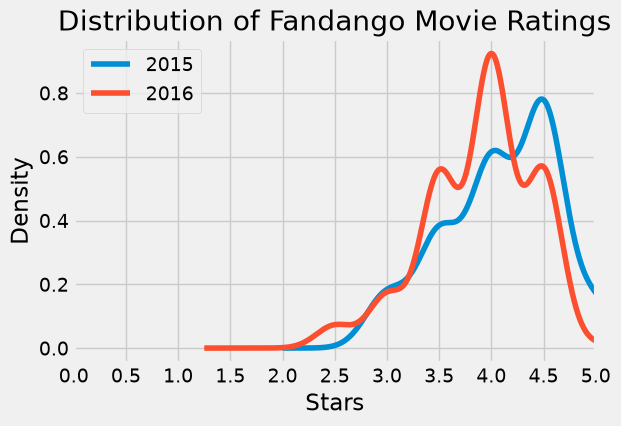

In [15]:
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

movies_2015['Fandango_Stars'].plot.kde(label='2015', legend=True, figsize=(6,4))
movies_2016['fandango'].plot.kde(label='2016', legend=True)

plt.title('Distribution of Fandango Movie Ratings')
plt.xlabel('Stars')
plt.xlim(0, 5)
plt.xticks([0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0])

Movies from both 2015 and 2016 have a distinctly left-skewed distribution. Movies from 2015 were rated slightly higher than those from 2016, peaking at 4.5 and 4.0 respectively. The overall left shift in distribution shows that there were indeed changes in movie ratings between the years. 

In [10]:
movies_2015['Fandango_Stars'].value_counts(normalize=True).sort_index() * 100

Fandango_Stars
3.0     8.527132
3.5    17.829457
4.0    28.682171
4.5    37.984496
5.0     6.976744
Name: proportion, dtype: float64

In [11]:
movies_2016['fandango'].value_counts(normalize=True).sort_index() * 100

fandango
2.5     3.141361
3.0     7.329843
3.5    24.083770
4.0    40.314136
4.5    24.607330
5.0     0.523560
Name: proportion, dtype: float64

The majority of ratings from both years are clustered in the 3.5-4.5 range. However, the frequency of top rated movies (4.5-5 stars) drops between 2015 and 2016 and we see more movie ratings in the range slightly below (3.5-4.0). In addition, the minimum rating drops from 3.0 to 2.5. 

We can see that the distribution has changed over time. Values at the ends of the distribution exhibit a left shift and values near the center of the distribution exhibit a right shift, bringing the graph closer to looking like a standard bell curve. 

## Summary Statistics

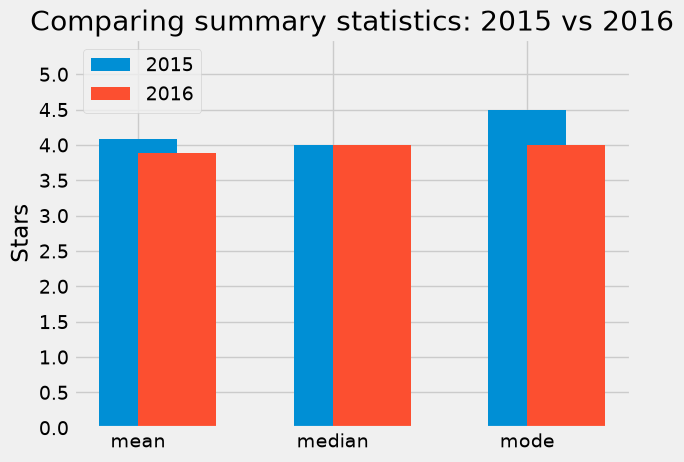

In [12]:
fig, ax = plt.subplots()

labels = ['mean', 'median', 'mode']
stats_2015 = [movies_2015['Fandango_Stars'].mean(), movies_2015['Fandango_Stars'].median(), movies_2015['Fandango_Stars'].mode()[0]]
stats_2016 = [movies_2016['fandango'].mean(), movies_2016['fandango'].median(), movies_2016['fandango'].mode()[0]]

ax.bar(labels, stats_2015, align='center', label='2015', width=0.4)
ax.bar(labels, stats_2016, align='edge', label='2016', width=0.4)

ax.set_title('Comparing summary statistics: 2015 vs 2016')
ax.set_ylabel('Stars')
ax.set_ylim(0.0, 5.5)
ax.set_yticks([0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0])
ax.legend()

In [13]:
((stats_2015[0] - stats_2016[0]) / stats_2015[0]) * 100

np.float64(4.842683568951993)

The mean of ratings in 2015 was almost 5% higher than 2016. The median was the same for both years. The mode for 2015 was half a star higher than 2016. This supports the previous statement that ratings for 2016 were, on average, lower than those in 2015.

## Conclusion
The movie ratings on Fandango have changed over time, dropping slightly from 2015 to 2016. It is possible that this is due to Fandango correcting their ratings after Hickey's discovery of inaccuracies in the system, but we would likely need more data to support this conclusion.